# Joint versus scArches: Full Group Concordance

- **Purpose:** Extend the MLM and GSEA concordance to the full cell line plus subpopulation matrix for both approaches.
- **Inputs:** Shared artifact; joint and scArches cached DE, GSEA, and MLM results.
- **Outputs:** Concordance CSVs under `models/validation/model_concordance/`; figures under `figures/BIOVAL/model_concordance/`.
- **Result:** Joint and scArches show the same block structure; the joint representation is used for the main concordance view.


In [1]:
from pathlib import Path
import re
import sys

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from sklearn.neighbors import NearestNeighbors

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils import load_config

cfg = load_config()

K_MATCHING = 100
JOINT_INPUT = Path.cwd() / "adata_config10_joint" / "config10_joint_3k.h5ad"
JOINT_DE = ROOT / cfg["paths"]["models"] / "validation" / "bio_joint_cfg10" / "de_signatures"
ARCHES_DE = ROOT / cfg["paths"]["models"] / "validation" / "bio_scarches_cfg47" / "de_signatures"
ARCHES_ARTIFACT = ARCHES_DE / "scarches_latent_groups.h5ad"
MLM_ARTIFACT = JOINT_DE / "hallmark_mlm" / "hallmark_mlm_scores.h5ad"
OUT_DIR = ROOT / cfg["paths"]["models"] / "validation" / "model_concordance"
FIG_DIR = ROOT / "figures" / "BIOVAL" / "model_concordance"

for directory in [OUT_DIR, FIG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

assert ARCHES_ARTIFACT.exists(), f"Run 4_Bio_scArches.ipynb first: {ARCHES_ARTIFACT}"
assert (ARCHES_DE / "gsea_hallmark" / "hallmark_prerank_tumor.csv").exists(), "scArches tumor GSEA missing"
assert (ARCHES_DE / "line_vs_tumor" / "hallmark_prerank_line_vs_tumor.csv").exists(), "scArches line-vs-subpopulation GSEA missing"
print("Inputs present")

Inputs present


In [2]:
combined_full = ad.read_h5ad(JOINT_INPUT)
arches = ad.read_h5ad(ARCHES_ARTIFACT)
assert combined_full.obs_names.equals(arches.obs_names)

dataset = combined_full.obs["dataset"].astype(str).to_numpy()
cell_lines = combined_full.obs["cell_line"].astype(str).to_numpy()
is_tumor = dataset == "tumor"
is_line = ~is_tumor

joint_groups = np.where(
    is_tumor,
    "tumor_" + combined_full.obs["tumor_leiden_res0.9"].astype(str).to_numpy(),
    "line_" + combined_full.obs["cell_line"].astype(str).to_numpy(),
)
arches_groups = arches.obs["match_group_scarches"].astype(str).to_numpy()


def tumor_group_sort_key(group):
    return int(str(group).rsplit("_", 1)[-1])


def group_order(group_values):
    return sorted(pd.unique(group_values[is_tumor]), key=tumor_group_sort_key)

# Matching

In [3]:
def knn_matches(latent, groups, k):
    latent = np.asarray(latent)
    groups = np.asarray(groups, dtype=str)
    nn = NearestNeighbors(n_neighbors=k, metric="euclidean").fit(latent[is_tumor])
    dist, idx = nn.kneighbors(latent[is_line])
    neighbor_groups = groups[is_tumor][idx]

    order = sorted(pd.unique(groups[is_tumor]), key=tumor_group_sort_key)
    composition = pd.DataFrame(
        {g: (neighbor_groups == g).mean(axis=1) for g in order},
        index=np.where(is_line)[0],
    )
    composition.insert(0, "cell_line", cell_lines[is_line])
    composition["nearest_tumor_distance"] = dist[:, 0]

    baseline_nn = NearestNeighbors(n_neighbors=2, metric="euclidean").fit(latent[is_tumor])
    baseline = float(np.quantile(baseline_nn.kneighbors(latent[is_tumor])[0][:, 1], 0.95))

    rows = []
    for cell_line in sorted(pd.unique(cell_lines[is_line])):
        cells = composition.loc[composition["cell_line"].eq(cell_line)]
        mean_comp = cells[order].mean().sort_values(ascending=False)
        rows.append({
            "cell_line": cell_line,
            "primary_match": mean_comp.index[0],
            "primary_frac": float(mean_comp.iloc[0]),
            "second_match": mean_comp.index[1],
            "second_frac": float(mean_comp.iloc[1]),
            "margin": float(mean_comp.iloc[0] - mean_comp.iloc[1]),
            "median_dist_nearest_tumor": float(cells["nearest_tumor_distance"].median()),
            "low_proximity": bool(cells["nearest_tumor_distance"].median() > baseline),
        })
    return pd.DataFrame(rows).set_index("cell_line"), baseline


joint_matches, joint_baseline = knn_matches(combined_full.obsm["X_latent"], joint_groups, K_MATCHING)
arches_matches, arches_baseline = knn_matches(arches.obsm["X_latent_scarches"], arches_groups, K_MATCHING)


def line_order_for(matches):
    return sorted(
        matches.index,
        key=lambda cl: (tumor_group_sort_key(matches.loc[cl, "primary_match"]), -float(matches.loc[cl, "margin"])),
    )


line_order_joint = line_order_for(joint_matches)
line_order_arches = line_order_for(arches_matches)
tumor_order_joint = group_order(joint_groups)
tumor_order_arches = group_order(arches_groups)

comparison = pd.DataFrame({
    "joint_primary": joint_matches["primary_match"],
    "arches_primary": arches_matches["primary_match"],
    "joint_margin": joint_matches["margin"],
    "arches_margin": arches_matches["margin"],
    "arches_low_proximity": arches_matches["low_proximity"],
})
comparison["same_primary"] = comparison["joint_primary"].eq(comparison["arches_primary"])
print(f"Joint q95 baseline:    {joint_baseline:.3f}")
print(f"scArches q95 baseline: {arches_baseline:.3f}")
display(comparison.round(3))

joint_matches.to_csv(OUT_DIR / "joint_line_matches_k100.csv")
arches_matches.to_csv(OUT_DIR / "arches_line_matches_k100.csv")

Joint q95 baseline:    1.631
scArches q95 baseline: 1.370


,joint_primary,arches_primary,joint_margin,arches_margin,arches_low_proximity,same_primary
cell_line,,,,,,
CCK81,tumor_5,tumor_2,0.256,0.305,False,False
CL34,tumor_4,tumor_2,0.022,0.527,False,False
HCC56,tumor_4,tumor_2,0.268,0.531,False,False
HT55,tumor_4,tumor_2,0.196,0.722,False,False
LS1034,tumor_4,tumor_2,0.084,0.049,False,False
LS180,tumor_4,tumor_2,0.141,0.710,False,False
NCIH747,tumor_5,tumor_2,0.123,0.707,False,False
OUMS23,tumor_6,tumor_2,0.192,0.589,True,False
RCM1,tumor_5,tumor_2,0.289,0.660,True,False


## Dominant Pelka Labels

In [4]:
def short_label(value):
    match = re.search(r"cE\d+", str(value))
    return match.group(0) if match else "?"


def dominant_labels(group_values):
    pelka = combined_full.obs["label"].astype(str).to_numpy()
    rows = []
    for group in pd.unique(group_values[is_tumor]):
        values = pelka[group_values == group]
        mode = pd.Series(values).mode().iloc[0]
        rows.append({
            "group": group,
            "n_cells": int(values.size),
            "dominant": short_label(mode),
            "share": round(float((values == mode).mean()), 2),
        })
    return pd.DataFrame(rows).sort_values("group", key=lambda s: s.map(tumor_group_sort_key))


print("Joint subpopulations")
display(dominant_labels(joint_groups).set_index("group"))
print("scArches subpopulations")
display(dominant_labels(arches_groups).set_index("group"))

Joint subpopulations


,n_cells,dominant,share
group,,,
tumor_0,12126,cE01,0.98
tumor_1,10323,cE01,0.98
tumor_2,3276,cE01,0.59
tumor_3,7047,cE01,0.84
tumor_4,11847,cE03,0.98
tumor_5,11858,cE03,0.99
tumor_6,1461,cE01,0.54
tumor_7,7357,cE01,0.96
tumor_8,11922,cE01,0.89


scArches subpopulations


,n_cells,dominant,share
group,,,
tumor_0,9417,cE01,0.96
tumor_1,9771,cE01,0.98
tumor_2,15032,cE03,0.95
tumor_3,8423,cE01,0.80
tumor_4,230,cE03,0.92
tumor_5,4390,cE03,0.97
tumor_6,8965,cE03,0.98
tumor_7,7006,cE01,0.81
tumor_8,1746,cE05,0.83


# MLM Concordance

In [5]:
mlm = ad.read_h5ad(MLM_ARTIFACT)
mlm_scores = pd.DataFrame(mlm.X, index=mlm.obs_names, columns=mlm.var_names).reindex(combined_full.obs_names)
assert mlm_scores.index.equals(combined_full.obs_names)


def mlm_group_profiles(group_values):
    groups = pd.Series(group_values, index=combined_full.obs_names, name="group")
    profiles = mlm_scores.join(groups).groupby("group", observed=True)[mlm_scores.columns].median()
    profiles.index = profiles.index.str.replace("^line_", "", regex=True)
    return profiles


def full_concordance(profiles, order):
    return profiles.loc[order].T.corr(method="spearman")


order_joint = line_order_joint + tumor_order_joint
order_arches = line_order_arches + tumor_order_arches
mlm_concordance_joint = full_concordance(mlm_group_profiles(joint_groups), order_joint)
mlm_concordance_arches = full_concordance(mlm_group_profiles(arches_groups), order_arches)
mlm_concordance_joint.to_csv(OUT_DIR / "mlm_concordance_full_joint.csv")
mlm_concordance_arches.to_csv(OUT_DIR / "mlm_concordance_full_arches.csv")
print(mlm_concordance_joint.shape, mlm_concordance_arches.shape)

(28, 28) (29, 29)


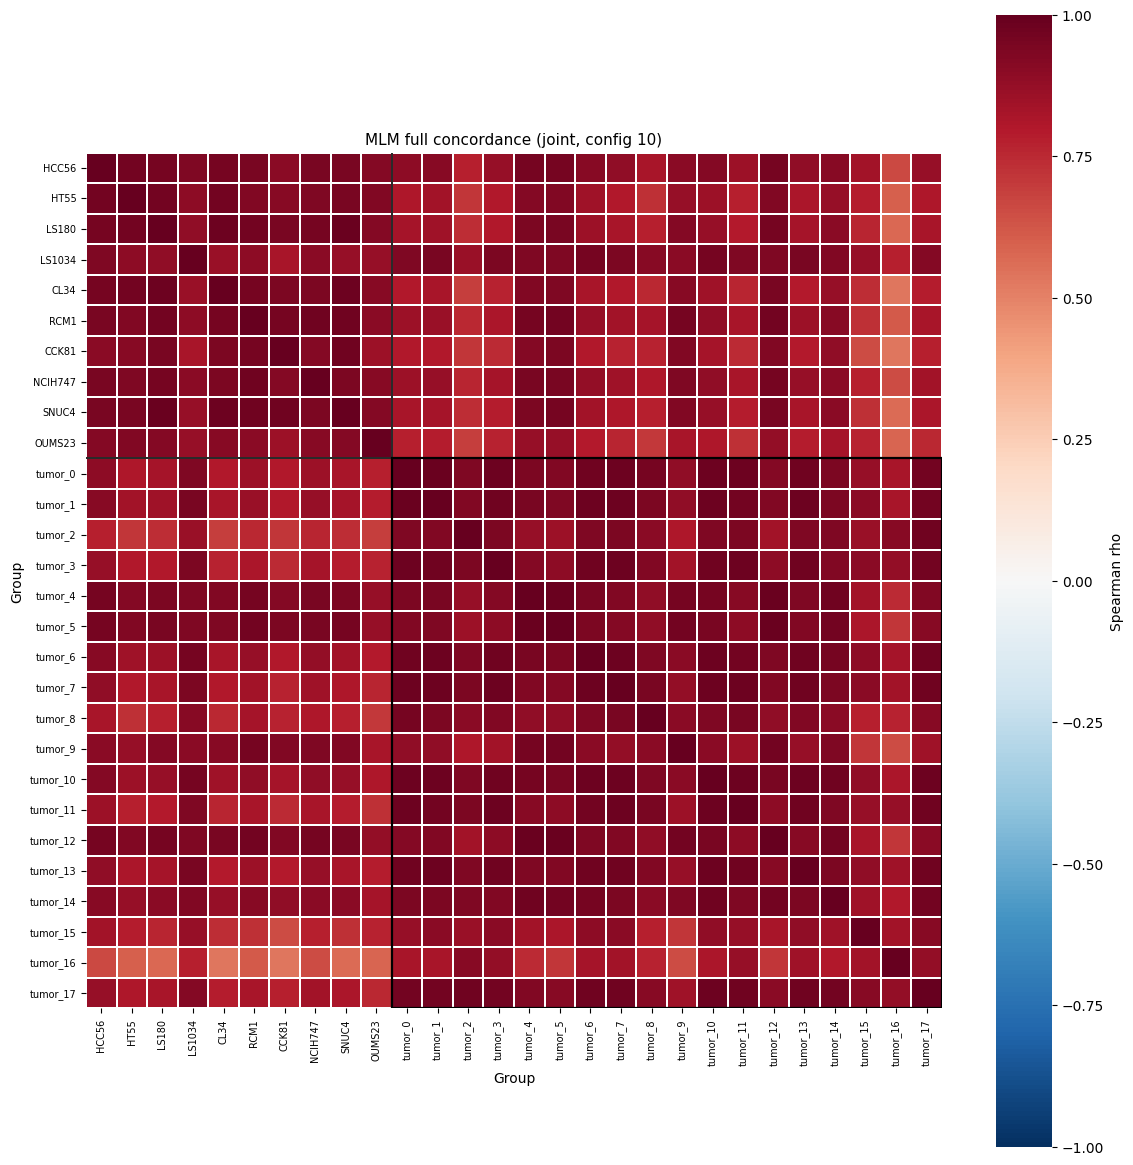

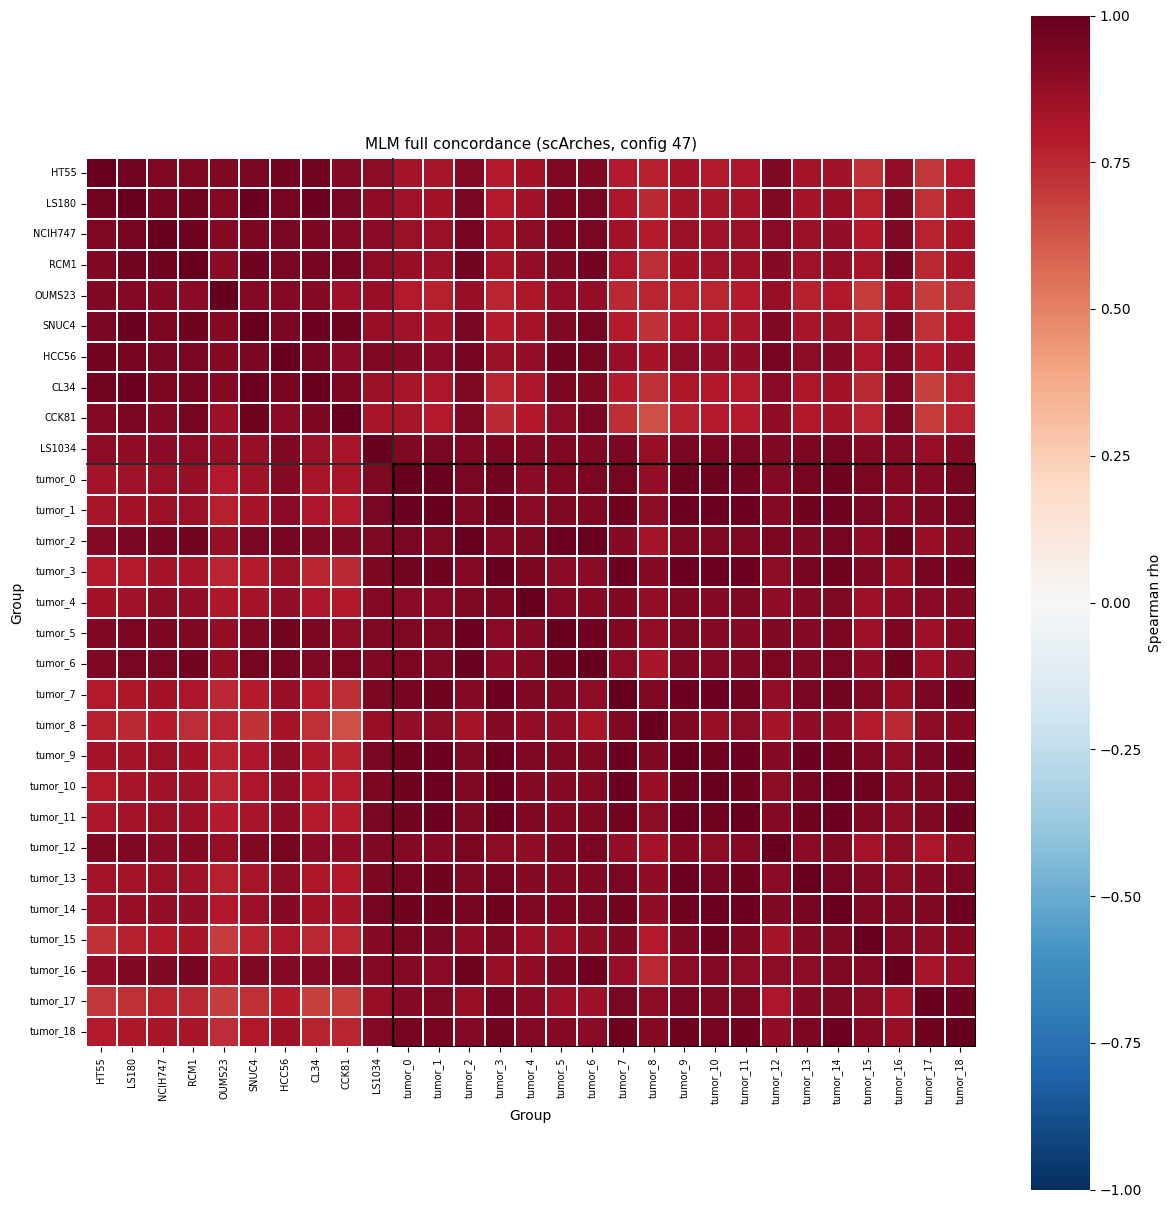

In [6]:
def plot_full_concordance(matrix, line_order, tumor_order, title, path):
    size = max(10, 0.42 * len(matrix))
    fig, ax = plt.subplots(figsize=(size, size))
    sns.heatmap(
        matrix, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
        linewidths=0.15, cbar_kws={"label": "Spearman rho"},
    )
    n = len(line_order)
    ax.axhline(n, color="black", linewidth=1.2)
    ax.axvline(n, color="black", linewidth=1.2)
    ax.add_patch(Rectangle((n, n), len(tumor_order), len(tumor_order),
                           fill=False, edgecolor="black", linewidth=1.6))
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=7)
    ax.set_xlabel("Group")
    ax.set_ylabel("Group")
    ax.set_title(title, fontsize=11)
    plt.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


plot_full_concordance(mlm_concordance_joint, line_order_joint, tumor_order_joint,
                      "MLM full concordance (joint, config 10)", FIG_DIR / "full_mlm_joint.png")
plot_full_concordance(mlm_concordance_arches, line_order_arches, tumor_order_arches,
                      "MLM full concordance (scArches, config 47)", FIG_DIR / "full_mlm_arches.png")

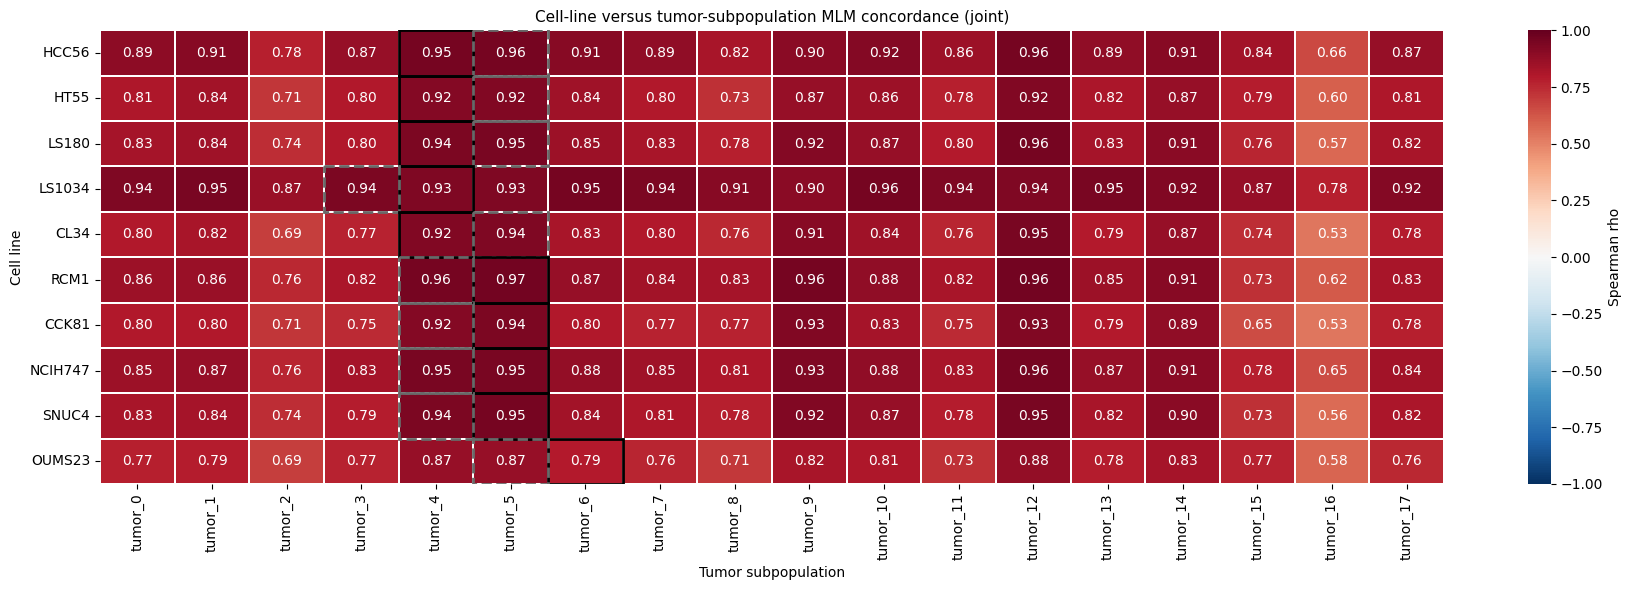

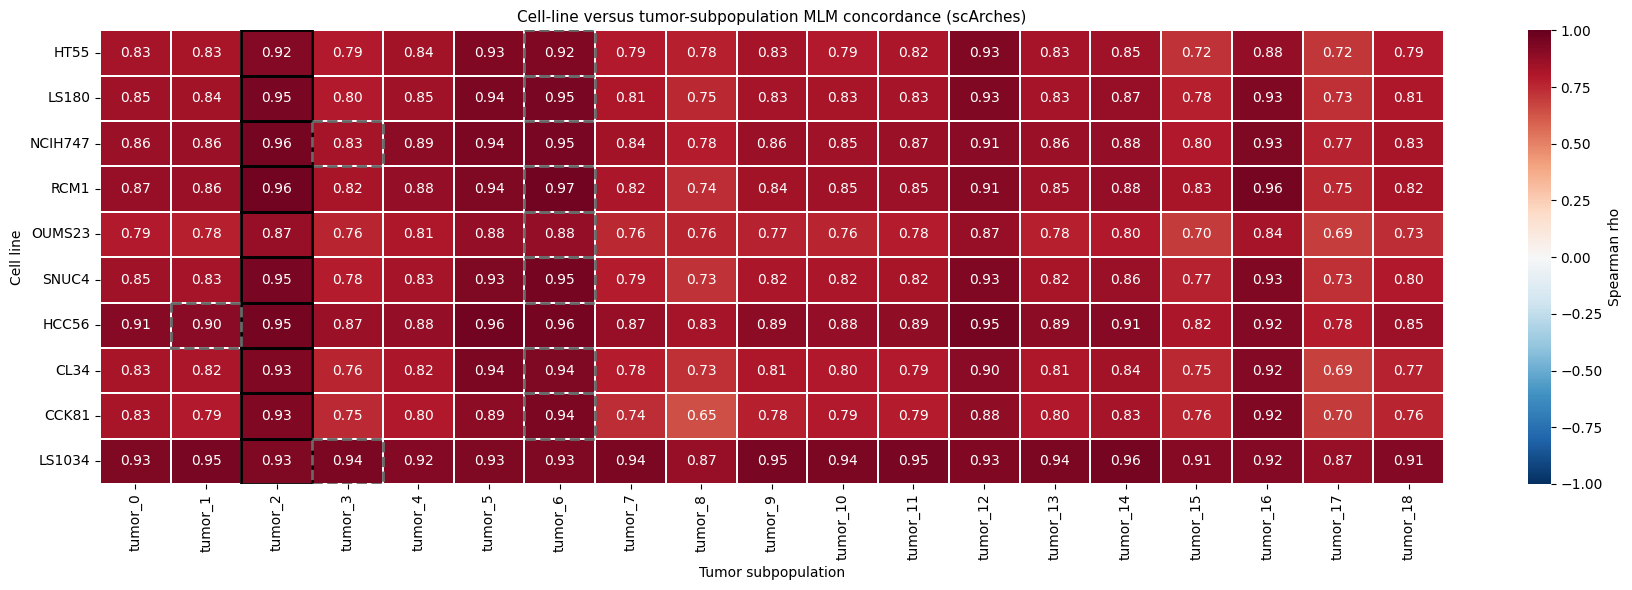

In [7]:
def plot_cl_subpop(matrix, line_order, tumor_order, matches, title, path):
    sub = matrix.loc[line_order, tumor_order]
    fig, ax = plt.subplots(figsize=(18, 6))
    sns.heatmap(
        sub, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
        annot=True, fmt=".2f", linewidths=0.3,
        cbar_kws={"label": "Spearman rho"},
    )
    for y, cell_line in enumerate(line_order):
        for group, color, linestyle in [
            (str(matches.loc[cell_line, "primary_match"]), "black", "-"),
            (str(matches.loc[cell_line, "second_match"]), "dimgray", "--"),
        ]:
            if group in tumor_order:
                ax.add_patch(Rectangle((tumor_order.index(group), y), 1, 1, fill=False,
                                       edgecolor=color, linewidth=2.0, linestyle=linestyle))
    ax.set_xlabel("Tumor subpopulation")
    ax.set_ylabel("Cell line")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)
    ax.set_title(title, fontsize=11)
    plt.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


plot_cl_subpop(mlm_concordance_joint, line_order_joint, tumor_order_joint, joint_matches,
               "Cell-line versus tumor-subpopulation MLM concordance (joint)", FIG_DIR / "cl_subpop_mlm_joint.png")
plot_cl_subpop(mlm_concordance_arches, line_order_arches, tumor_order_arches, arches_matches,
               "Cell-line versus tumor-subpopulation MLM concordance (scArches)", FIG_DIR / "cl_subpop_mlm_arches.png")

# GSEA Signature

In [8]:
def load_signature(de_dir):
    gsea_tumor = pd.read_csv(de_dir / "gsea_hallmark" / "hallmark_prerank_tumor.csv")
    gsea_line = pd.read_csv(de_dir / "line_vs_tumor" / "hallmark_prerank_line_vs_tumor.csv")
    tumor_signature = gsea_tumor.pivot_table(index="pathway", columns="subpopulation", values="nes")
    line_signature = (
        gsea_line.groupby(["cell_line", "pathway"], observed=True)["nes"].mean().unstack("pathway")
    )
    return line_signature, tumor_signature


def signature_concordance(line_signature, tumor_signature, order, exclude=()):
    profiles = pd.concat([line_signature, tumor_signature.T], axis=0).loc[order]
    pathways = [p for p in profiles.columns if p not in set(exclude)]
    return profiles[pathways].T.corr(method="spearman")


line_signature_joint, tumor_signature_joint = load_signature(JOINT_DE)
line_signature_arches, tumor_signature_arches = load_signature(ARCHES_DE)

shared_proliferation = ["E2F_TARGETS", "G2M_CHECKPOINT", "MITOTIC_SPINDLE", "MYC_TARGETS_V1"]
signature_concordance_joint = signature_concordance(line_signature_joint, tumor_signature_joint, order_joint)
signature_concordance_arches = signature_concordance(line_signature_arches, tumor_signature_arches, order_arches)
signature_concordance_joint_noprolif = signature_concordance(line_signature_joint, tumor_signature_joint, order_joint, exclude=shared_proliferation)
signature_concordance_arches_noprolif = signature_concordance(line_signature_arches, tumor_signature_arches, order_arches, exclude=shared_proliferation)

for name, matrix in {
    "signature_concordance_full_joint.csv": signature_concordance_joint,
    "signature_concordance_full_arches.csv": signature_concordance_arches,
    "signature_concordance_full_joint_noprolif.csv": signature_concordance_joint_noprolif,
    "signature_concordance_full_arches_noprolif.csv": signature_concordance_arches_noprolif,
}.items():
    matrix.to_csv(OUT_DIR / name)

print(signature_concordance_joint.shape, signature_concordance_arches.shape)

(28, 28) (29, 29)


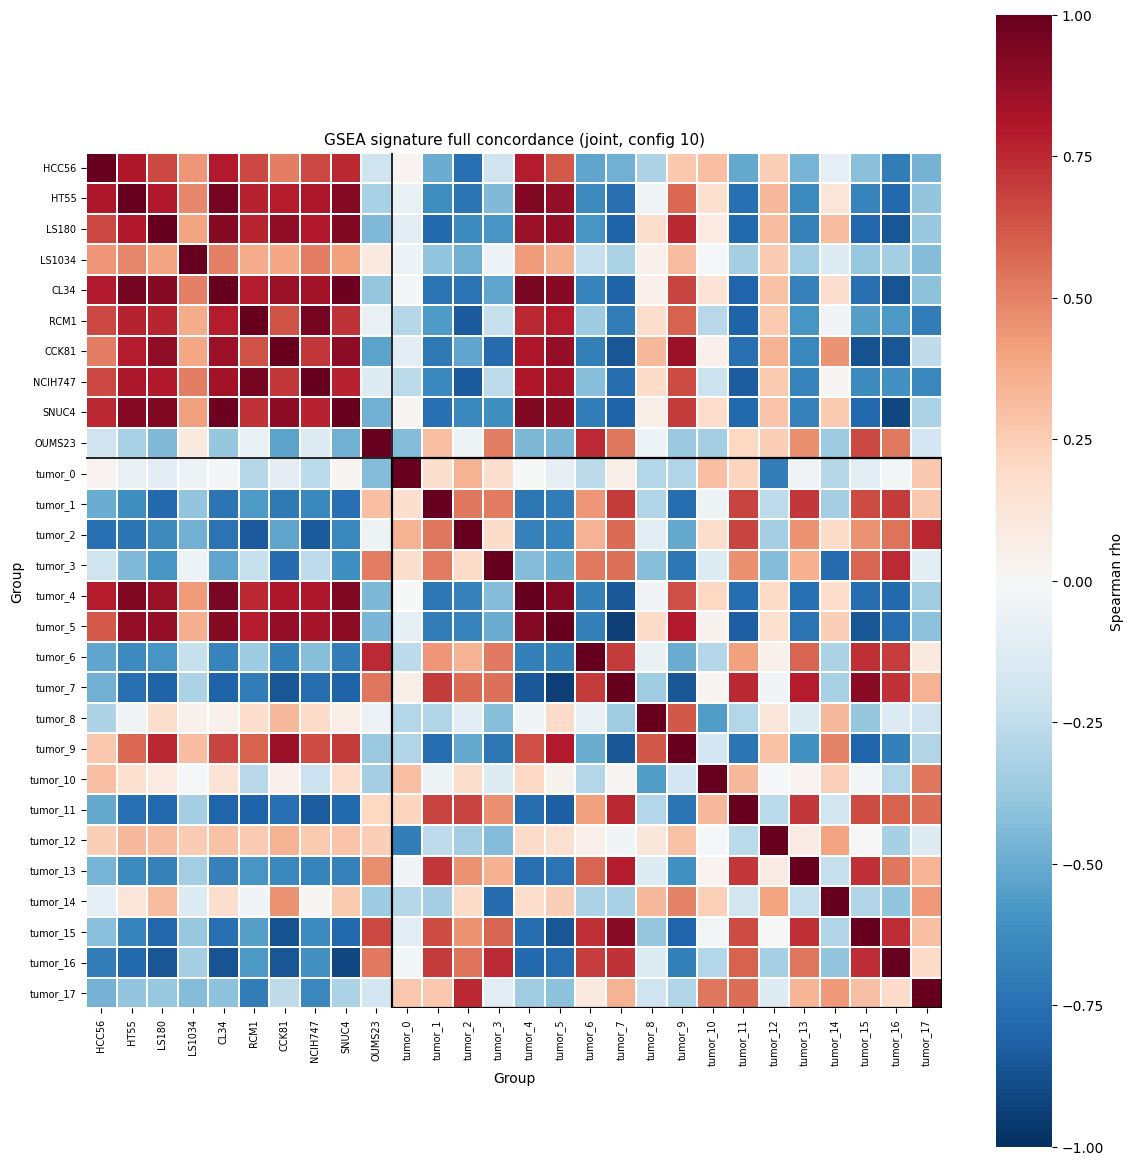

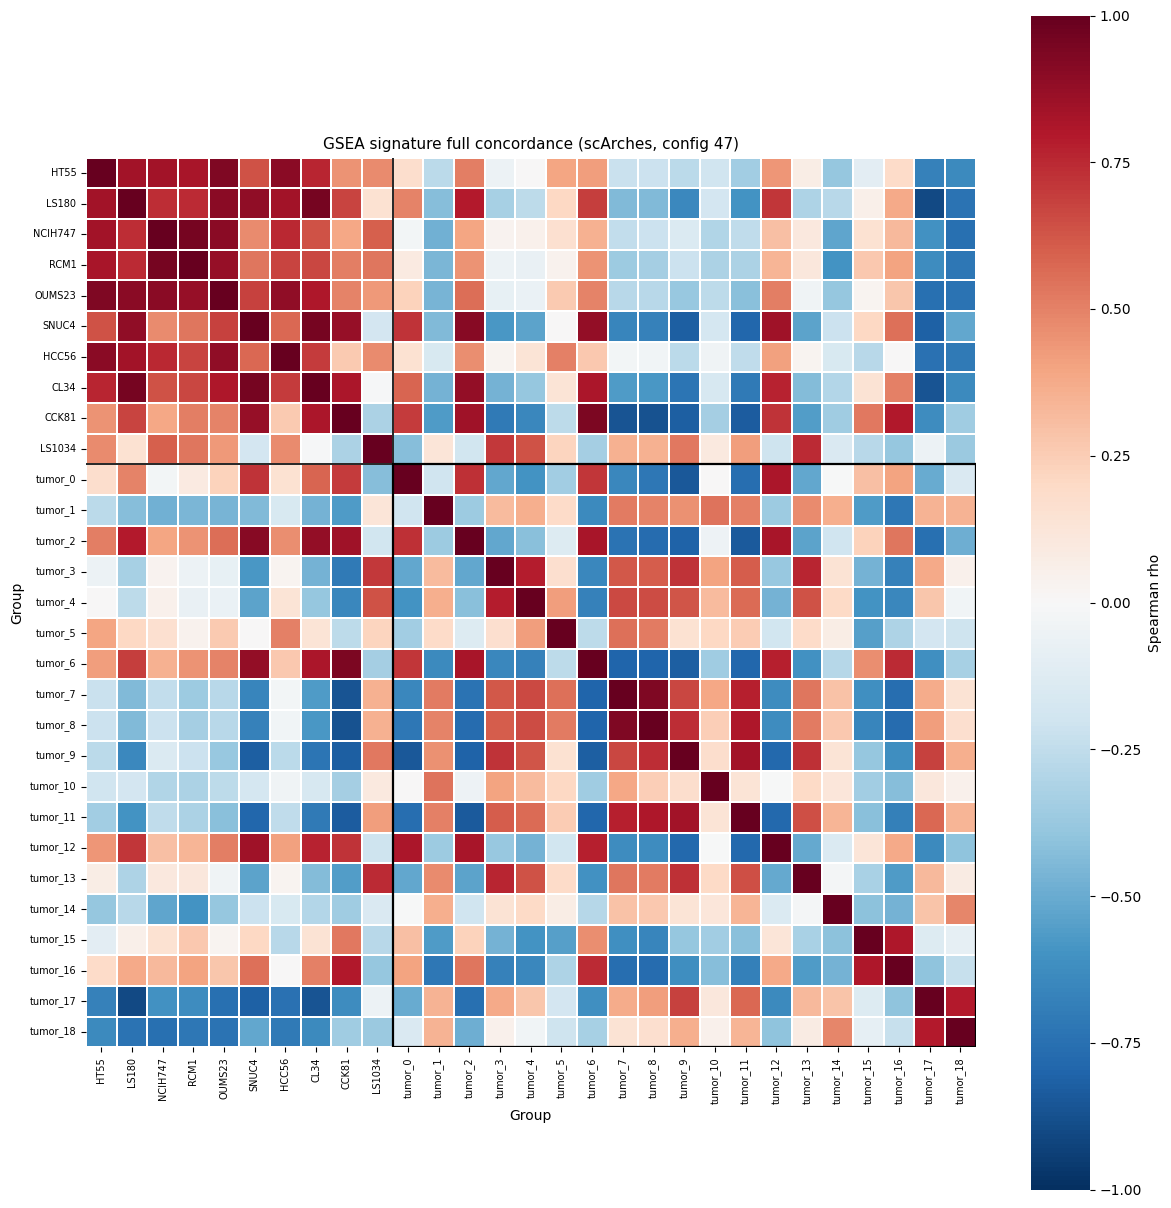

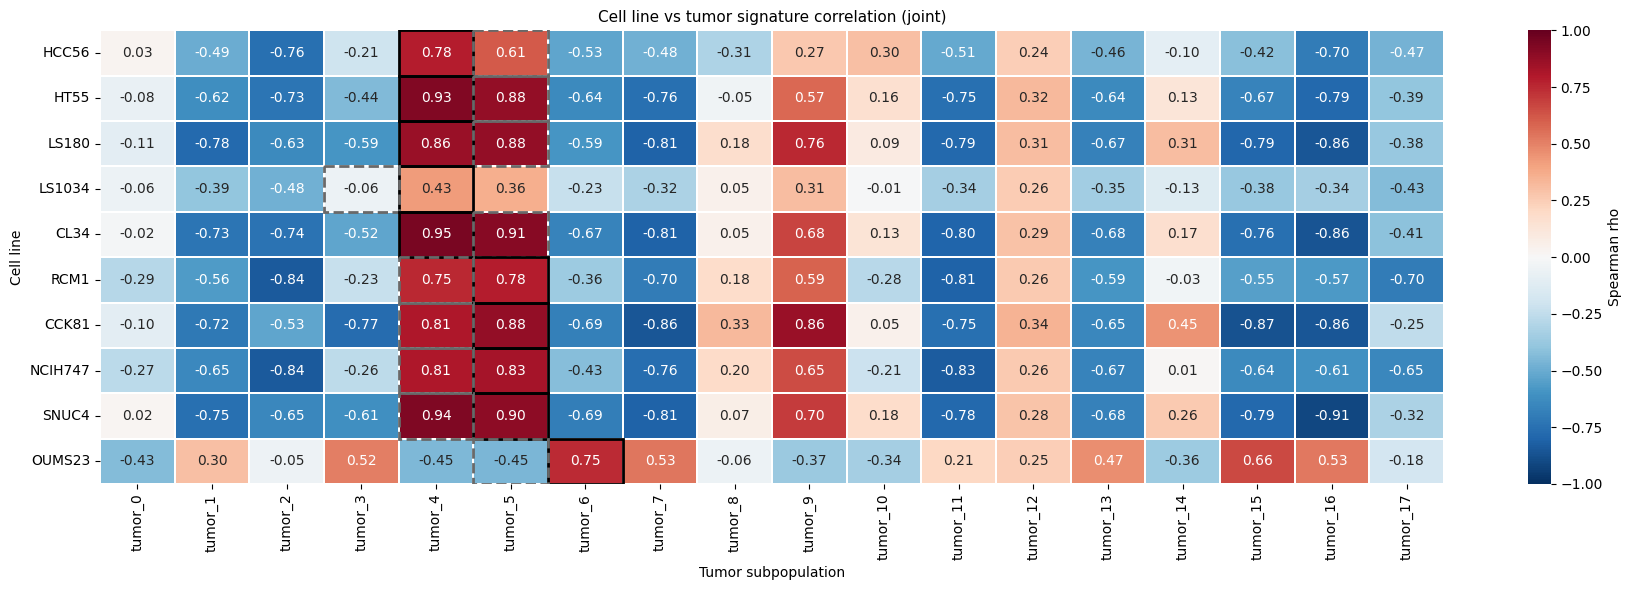

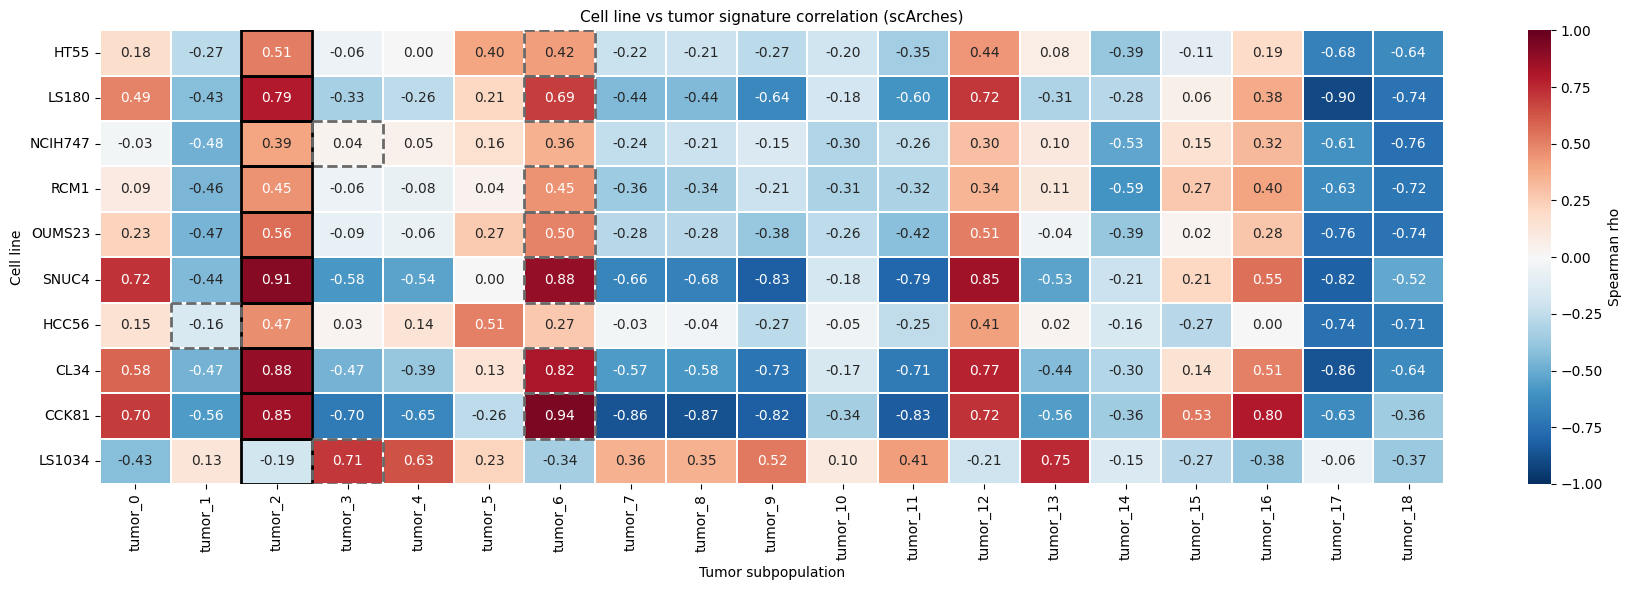

In [9]:
plot_full_concordance(signature_concordance_joint, line_order_joint, tumor_order_joint,
                      "GSEA signature full concordance (joint, config 10)", FIG_DIR / "full_signature_joint.png")
plot_full_concordance(signature_concordance_arches, line_order_arches, tumor_order_arches,
                      "GSEA signature full concordance (scArches, config 47)", FIG_DIR / "full_signature_arches.png")
plot_cl_subpop(signature_concordance_joint, line_order_joint, tumor_order_joint, joint_matches,
               "Cell line vs tumor signature correlation (joint)", FIG_DIR / "cl_subpop_signature_joint.png")
plot_cl_subpop(signature_concordance_arches, line_order_arches, tumor_order_arches, arches_matches,
               "Cell line vs tumor signature correlation (scArches)", FIG_DIR / "cl_subpop_signature_arches.png")

# test

In [10]:
def block_summary(matrix, line_order, tumor_order):
    cell_line_block = matrix.loc[line_order, line_order].to_numpy()
    cell_line_block = cell_line_block[~np.eye(len(line_order), dtype=bool)]
    subpop_block = matrix.loc[tumor_order, tumor_order].to_numpy()
    subpop_block = subpop_block[~np.eye(len(tumor_order), dtype=bool)]
    cross_block = matrix.loc[line_order, tumor_order].to_numpy().ravel()
    return pd.Series({
        "CL-CL mean": cell_line_block.mean(), "CL-SP mean": cross_block.mean(), "SP-SP mean": subpop_block.mean(),
        "CL-CL min": cell_line_block.min(), "CL-SP min": cross_block.min(), "SP-SP min": subpop_block.min(),
    }).round(3)


block_table = pd.DataFrame({
    "MLM joint": block_summary(mlm_concordance_joint, line_order_joint, tumor_order_joint),
    "MLM scArches": block_summary(mlm_concordance_arches, line_order_arches, tumor_order_arches),
    "signature joint": block_summary(signature_concordance_joint, line_order_joint, tumor_order_joint),
    "signature scArches": block_summary(signature_concordance_arches, line_order_arches, tumor_order_arches),
})
block_table.to_csv(OUT_DIR / "block_summary.csv")
display(block_table)


def related_groups(matrix, group, n=6):
    row = matrix.loc[group].drop(group).sort_values(ascending=False)
    return {
        "group": group,
        "top": ", ".join(f"{g} {v:.2f}" for g, v in row.head(n).items()),
        "bottom": ", ".join(f"{g} {v:.2f}" for g, v in row.tail(n).items()),
    }


for label, matrix in [("MLM joint", mlm_concordance_joint), ("signature joint", signature_concordance_joint)]:
    for group in ["tumor_4", "tumor_16"]:
        if group in matrix.index:
            record = related_groups(matrix, group)
            print(f"{label} | {record['group']}")
            print(f"  top:    {record['top']}")
            print(f"  bottom: {record['bottom']}")

arches_annotation = dominant_labels(arches_groups)
cE03_groups = arches_annotation.loc[arches_annotation["dominant"].eq("cE03"), "group"].tolist()
print(f"scArches cE03-dominated groups: {cE03_groups}")
for group in cE03_groups[:2]:
    record = related_groups(signature_concordance_arches, group)
    print(f"signature scArches | {record['group']}")
    print(f"  top:    {record['top']}")
    print(f"  bottom: {record['bottom']}")

if "LS1034" in signature_concordance_joint.index:
    row = signature_concordance_joint.loc["LS1034"].loc[line_order_joint].drop("LS1034").sort_values(ascending=False)
    print("signature joint | LS1034 vs other cell lines: " + ", ".join(f"{g} {v:.2f}" for g, v in row.items()))

print("Saved CSVs:")
for path in sorted(OUT_DIR.glob("*.csv")):
    print(" ", path.name)
print("Saved figures:")
for path in sorted(FIG_DIR.glob("*.png")):
    print(" ", path.name)

,MLM joint,MLM scArches,signature joint,signature scArches
CL-CL mean,0.930,0.930,0.520,0.634
CL-SP mean,0.836,0.849,-0.166,-0.085
SP-SP mean,0.916,0.926,0.017,0.003
CL-CL min,0.823,0.823,-0.537,-0.313
CL-SP min,0.532,0.647,-0.908,-0.902
SP-SP min,0.649,0.756,-0.941,-0.851


MLM joint | tumor_4
  top:    tumor_5 0.99, tumor_12 0.98, tumor_14 0.97, tumor_10 0.96, RCM1 0.96, tumor_9 0.96
  bottom: tumor_11 0.91, tumor_8 0.89, tumor_2 0.87, OUMS23 0.87, tumor_15 0.84, tumor_16 0.75
MLM joint | tumor_16
  top:    tumor_2 0.91, tumor_17 0.88, tumor_3 0.88, tumor_11 0.87, tumor_13 0.84, tumor_7 0.84
  bottom: HT55 0.60, OUMS23 0.58, LS180 0.57, SNUC4 0.56, CL34 0.53, CCK81 0.53
signature joint | tumor_4
  top:    CL34 0.95, SNUC4 0.94, HT55 0.93, tumor_5 0.92, LS180 0.86, CCK81 0.81
  bottom: tumor_1 -0.73, tumor_13 -0.75, tumor_15 -0.76, tumor_11 -0.76, tumor_16 -0.78, tumor_7 -0.84
signature joint | tumor_16
  top:    tumor_3 0.75, tumor_15 0.74, tumor_7 0.72, tumor_1 0.70, tumor_6 0.69, tumor_11 0.59
  bottom: tumor_4 -0.78, HT55 -0.79, LS180 -0.86, CCK81 -0.86, CL34 -0.86, SNUC4 -0.91
scArches cE03-dominated groups: ['tumor_2', 'tumor_4', 'tumor_5', 'tumor_6', 'tumor_12', 'tumor_16']
signature scArches | tumor_2
  top:    SNUC4 0.91, CL34 0.88, CCK81 0.85, t

## pathway z score

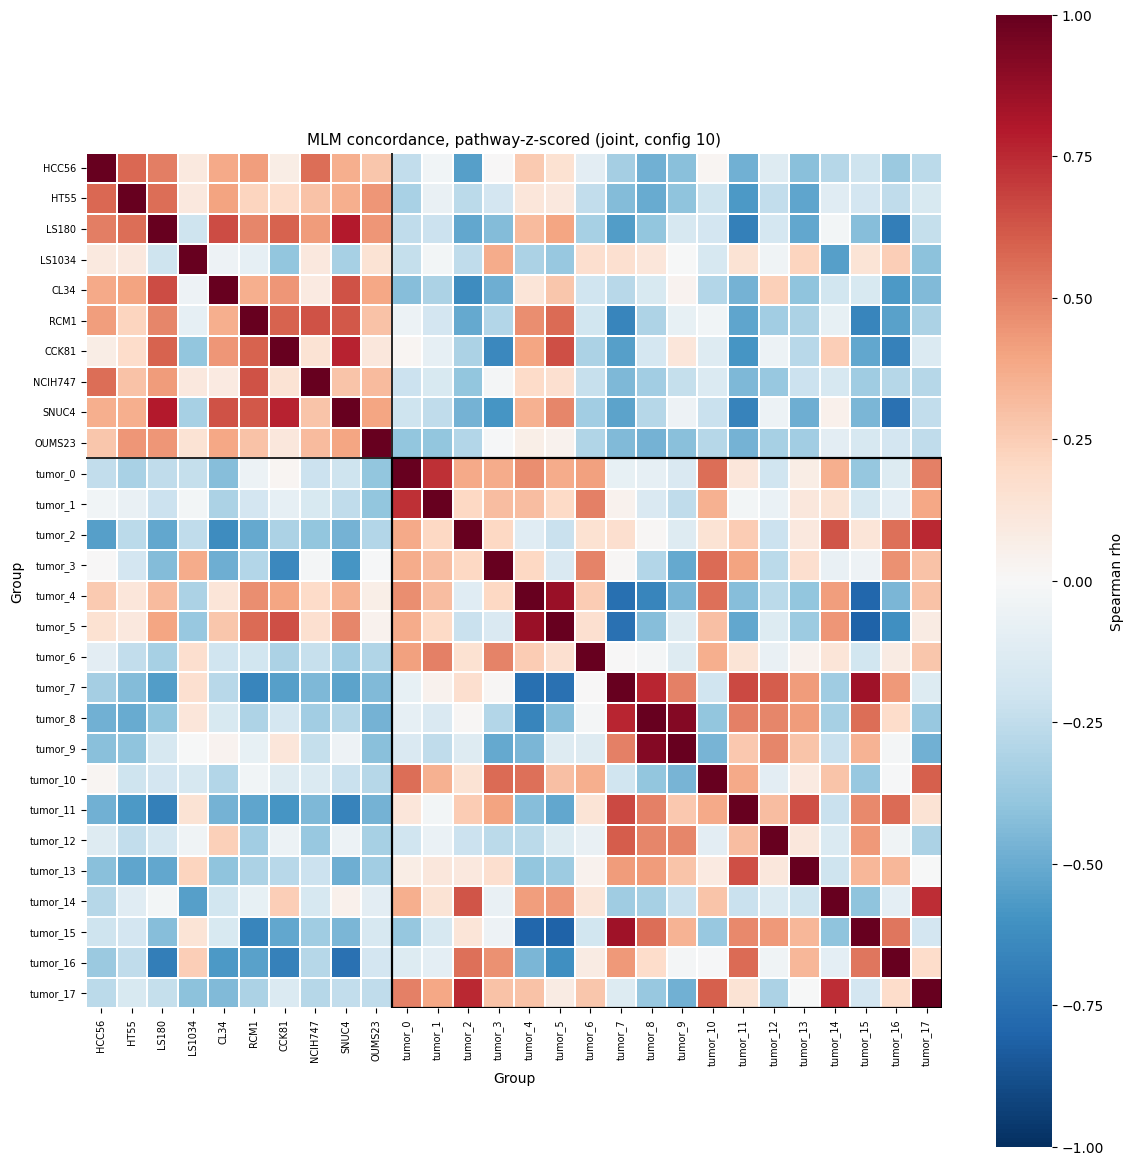

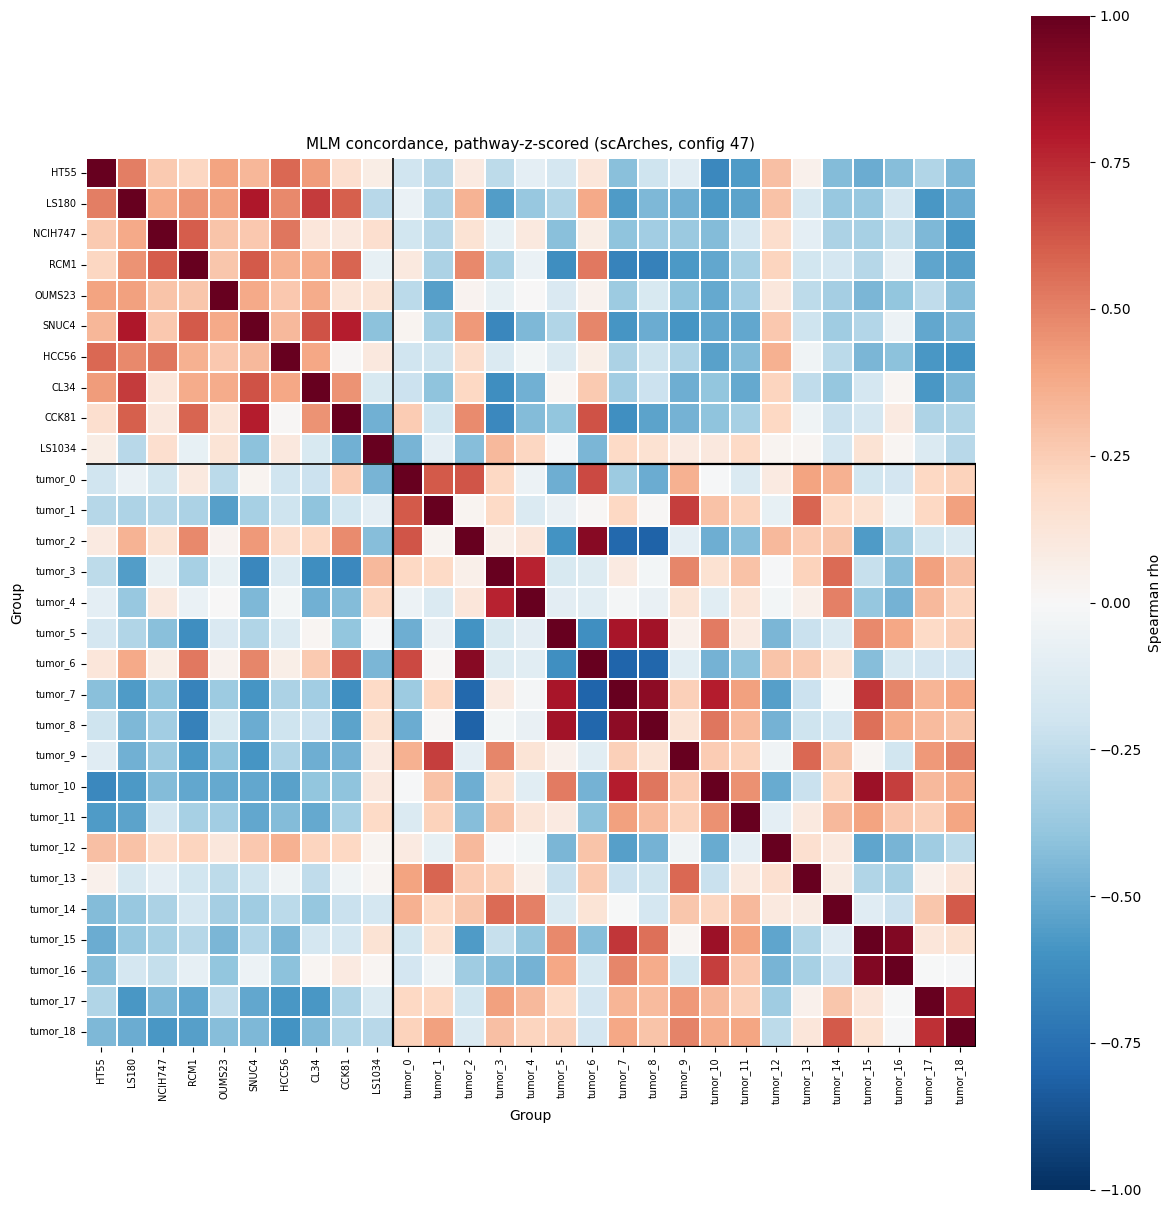

In [11]:
def zscored_group_concordance(profiles, order):
    p = profiles.loc[order].astype(float)
    sd = p.std(axis=0, ddof=0)
    keep = sd > 0
    z = (p.loc[:, keep] - p.loc[:, keep].mean(axis=0)) / sd[keep]
    return z.T.corr(method="pearson")


mlm_concordance_joint_z = zscored_group_concordance(mlm_group_profiles(joint_groups), order_joint)
mlm_concordance_arches_z = zscored_group_concordance(mlm_group_profiles(arches_groups), order_arches)
mlm_concordance_joint_z.to_csv(OUT_DIR / "mlm_concordance_z_joint.csv")
mlm_concordance_arches_z.to_csv(OUT_DIR / "mlm_concordance_z_arches.csv")

plot_full_concordance(
    mlm_concordance_joint_z, line_order_joint, tumor_order_joint,
    "MLM concordance, pathway-z-scored (joint, config 10)", FIG_DIR / "full_mlm_z_joint.png",
)
plot_full_concordance(
    mlm_concordance_arches_z, line_order_arches, tumor_order_arches,
    "MLM concordance, pathway-z-scored (scArches, config 47)", FIG_DIR / "full_mlm_z_arches.png",
)

## latent distance, same size

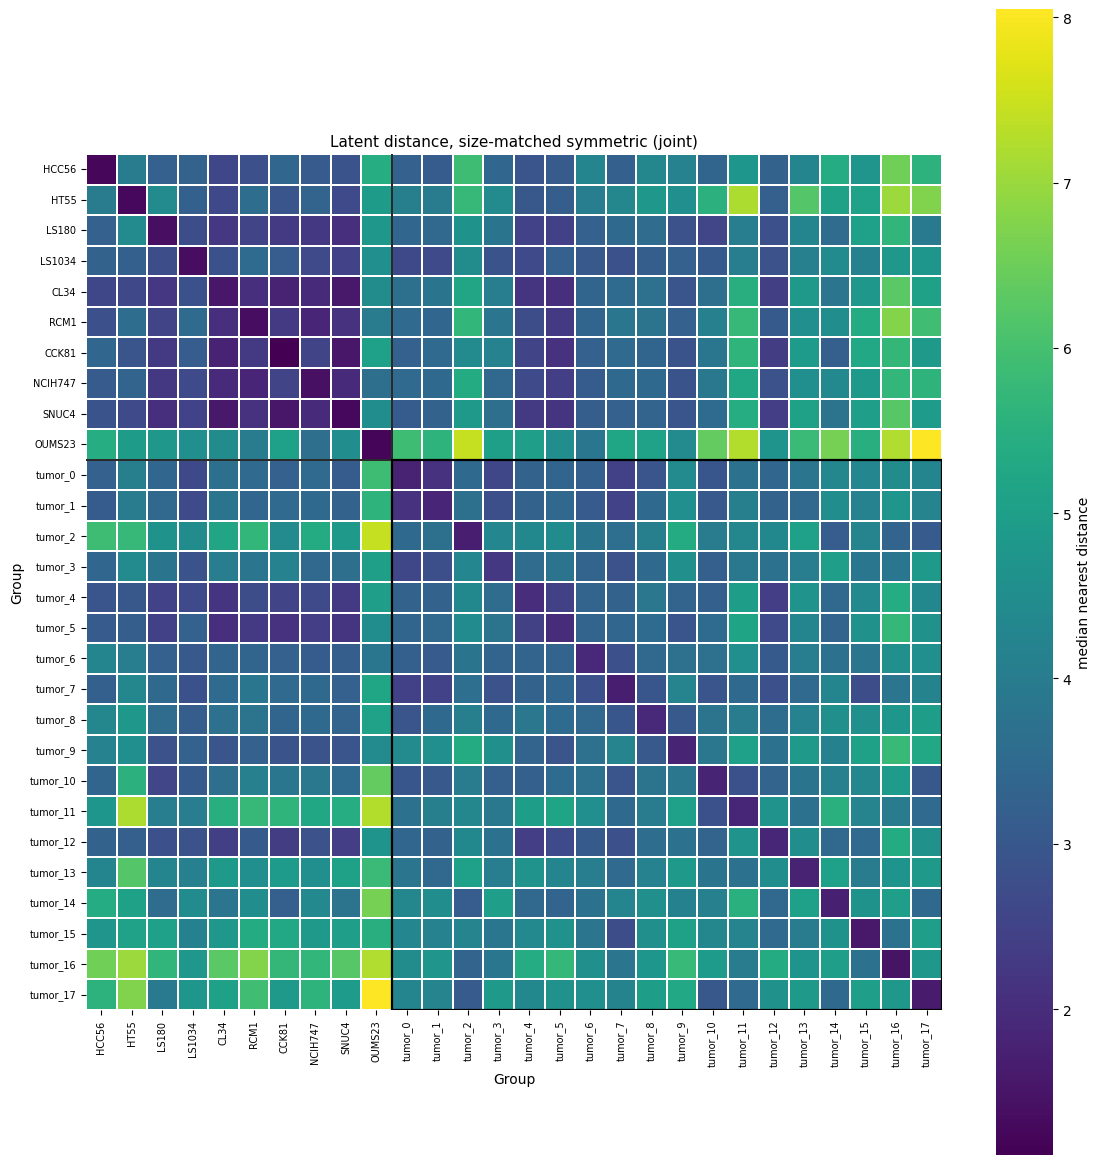

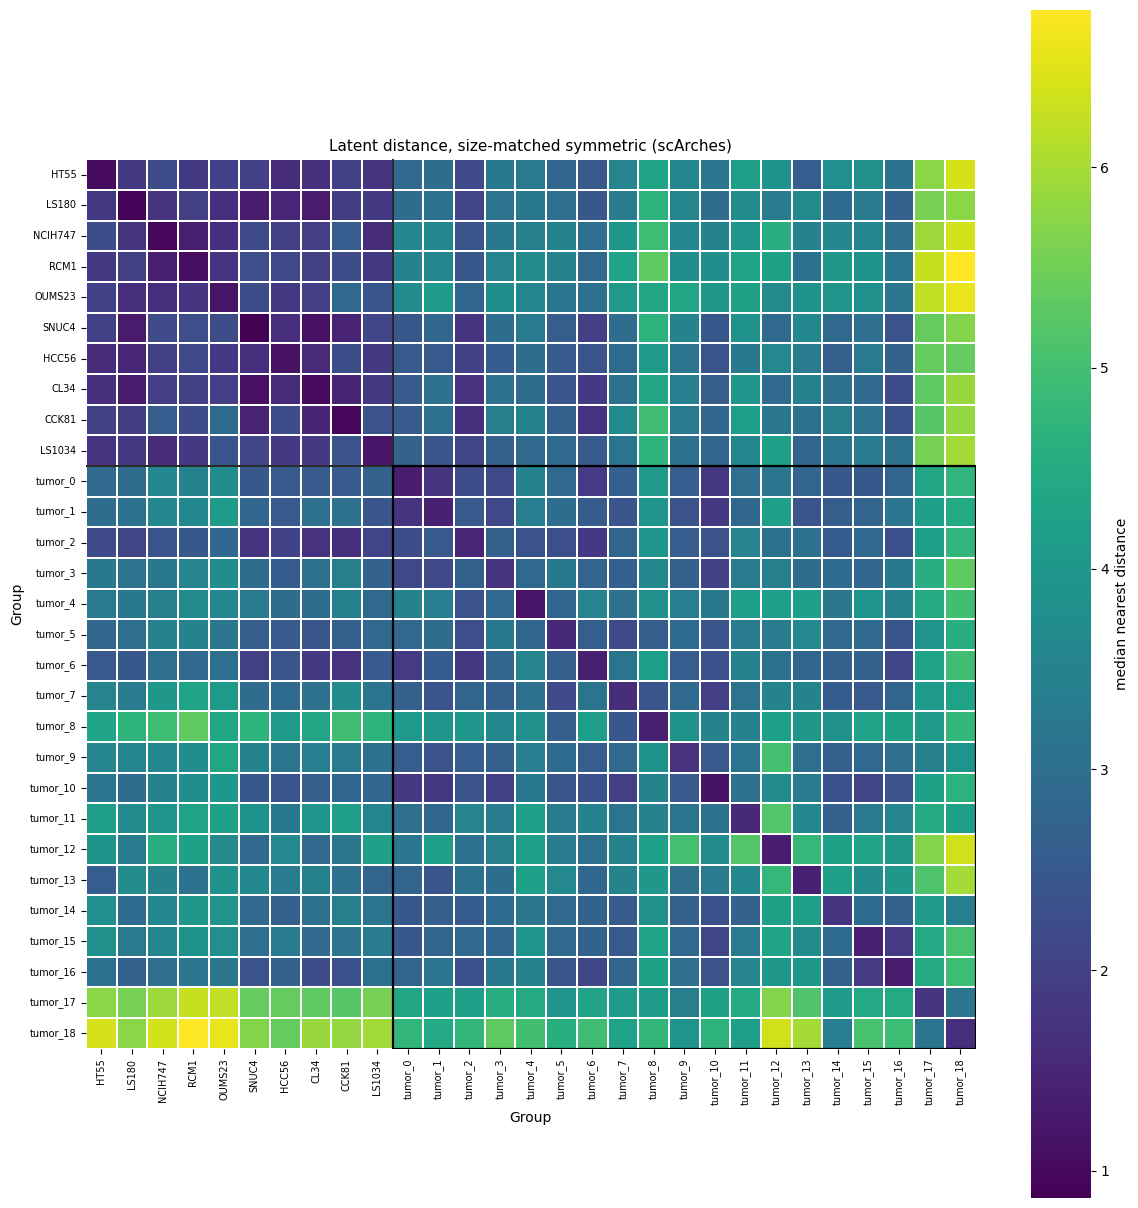

In [12]:
SUBSAMPLE_N = 80


def bare_group_labels(group_values):
    return np.asarray(pd.Series(group_values).str.replace(r"^line_", "", regex=True))


def symmetric_nn_distance(latent, labels, group_list, n, seed=0):
    latent = np.asarray(latent)
    labels = np.asarray(labels, dtype=str)
    rng = np.random.default_rng(seed)
    sampled = {}
    for group in group_list:
        members = np.where(labels == group)[0]
        assert members.size >= n, (group, members.size)
        sampled[group] = latent[rng.choice(members, size=n, replace=False)]
    distance = pd.DataFrame(np.nan, index=group_list, columns=group_list)
    for target in group_list:
        nn = NearestNeighbors(n_neighbors=1, metric="euclidean").fit(sampled[target])
        for source in group_list:
            if source == target:
                continue
            d, _ = nn.kneighbors(sampled[source])
            distance.loc[source, target] = float(np.median(d[:, 0]))
        nn_self = NearestNeighbors(n_neighbors=2, metric="euclidean").fit(sampled[target])
        d_self, _ = nn_self.kneighbors(sampled[target])
        distance.loc[target, target] = float(np.median(d_self[:, 1]))
    return (distance + distance.T) / 2


def plot_group_heatmap(matrix, line_order, tumor_order, title, path, cmap,
                       center=None, vmin=None, vmax=None, cbar_label=""):
    size = max(10, 0.42 * len(matrix))
    fig, ax = plt.subplots(figsize=(size, size))
    sns.heatmap(
        matrix, ax=ax, cmap=cmap, center=center, vmin=vmin, vmax=vmax,
        square=True, linewidths=0.15, cbar_kws={"label": cbar_label},
    )
    n, m = len(line_order), len(tumor_order)
    ax.axhline(n, color="black", linewidth=1.2)
    ax.axvline(n, color="black", linewidth=1.2)
    ax.add_patch(Rectangle((n, n), m, m, fill=False, edgecolor="black", linewidth=1.6))
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=7)
    ax.set_xlabel("Group")
    ax.set_ylabel("Group")
    ax.set_title(title, fontsize=11)
    plt.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


labels_joint = bare_group_labels(joint_groups)
labels_arches = bare_group_labels(arches_groups)

latent_distance_joint = symmetric_nn_distance(combined_full.obsm["X_latent"], labels_joint, order_joint, SUBSAMPLE_N)
latent_distance_arches = symmetric_nn_distance(arches.obsm["X_latent_scarches"], labels_arches, order_arches, SUBSAMPLE_N)
latent_distance_joint.to_csv(OUT_DIR / "latent_distance_joint.csv")
latent_distance_arches.to_csv(OUT_DIR / "latent_distance_arches.csv")

plot_group_heatmap(
    latent_distance_joint, line_order_joint, tumor_order_joint,
    "Latent distance, size-matched symmetric (joint)", FIG_DIR / "full_latent_distance_joint.png",
    cmap="viridis", cbar_label="median nearest distance",
)
plot_group_heatmap(
    latent_distance_arches, line_order_arches, tumor_order_arches,
    "Latent distance, size-matched symmetric (scArches)", FIG_DIR / "full_latent_distance_arches.png",
    cmap="viridis", cbar_label="median nearest distance",
)

## kNN composition, lob obs vs expected

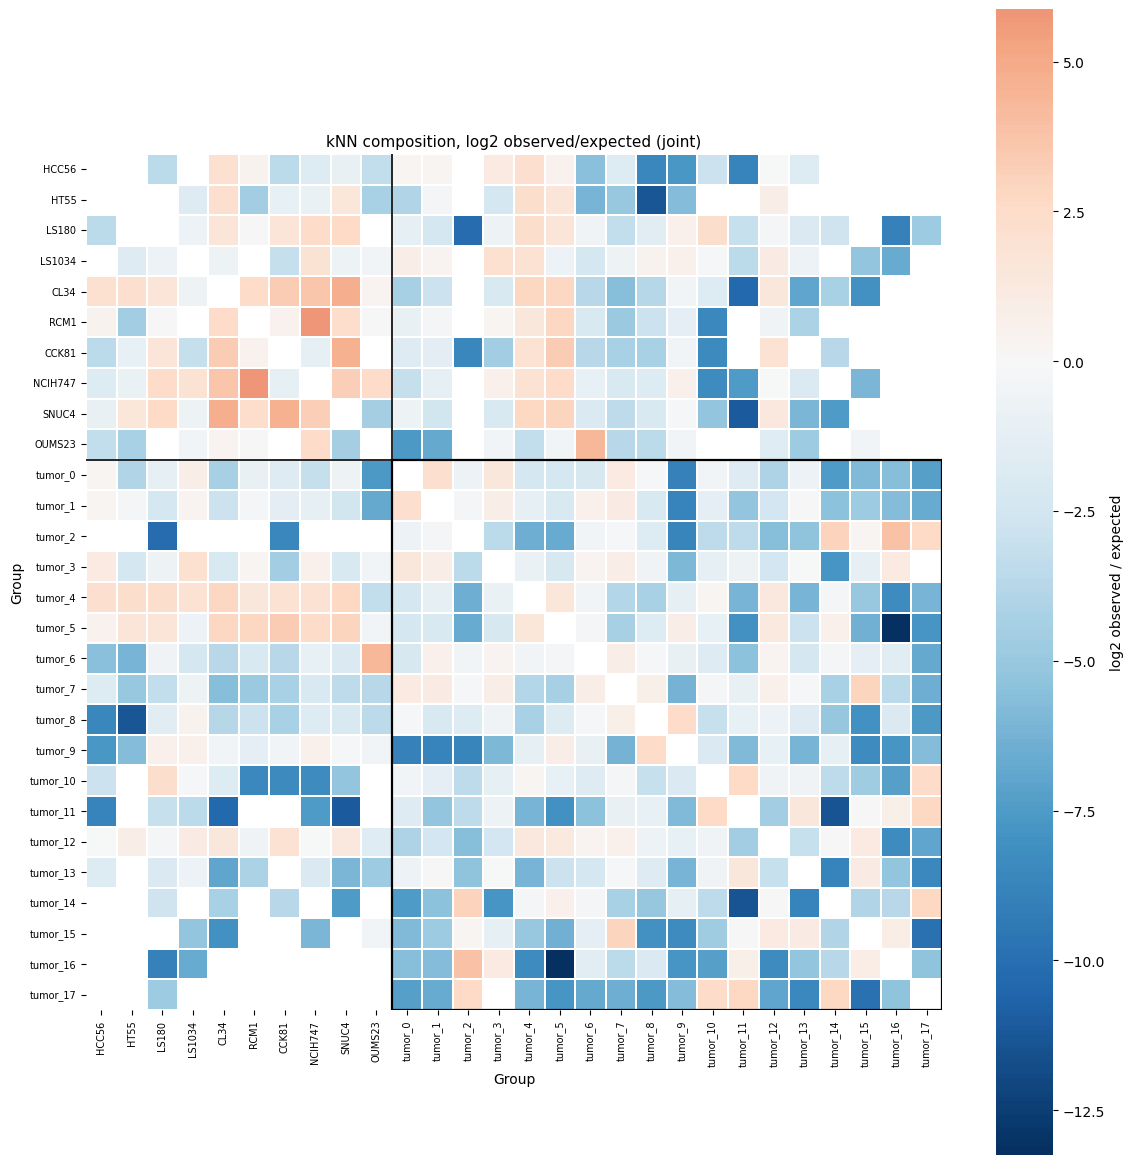

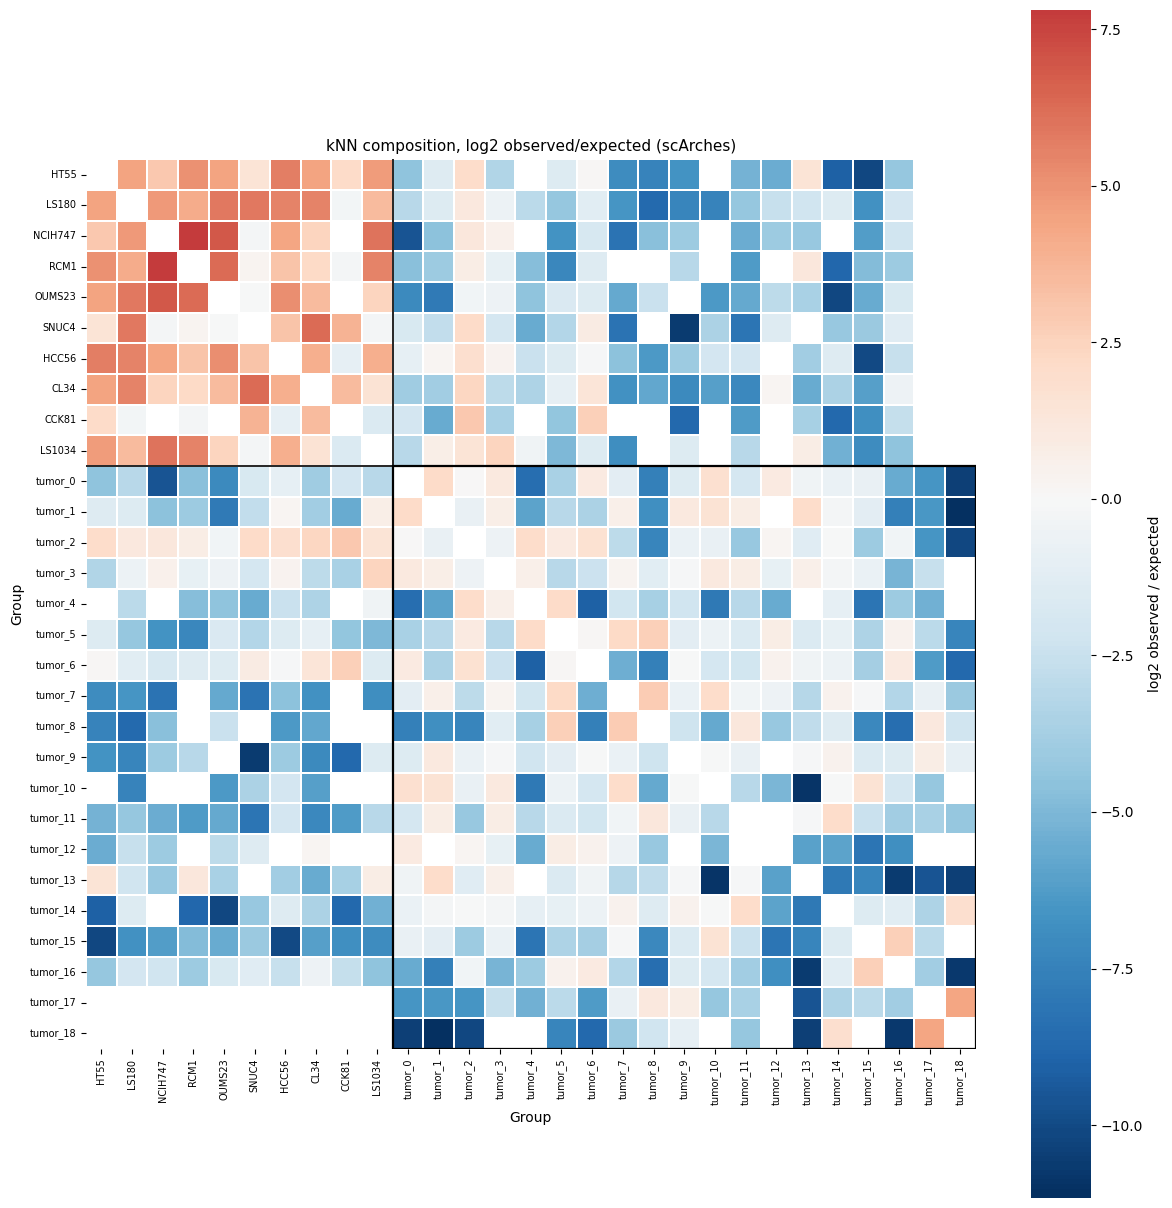

In [13]:
def all_vs_all_knn_oe(latent, labels, group_list, k):
    latent = np.asarray(latent)
    labels = np.asarray(labels, dtype=str)
    sizes = {group: int((labels == group).sum()) for group in group_list}
    oe = pd.DataFrame(np.nan, index=group_list, columns=group_list)
    for source in group_list:
        source_mask = labels == source
        pool_mask = ~source_mask
        pool_groups = labels[pool_mask]
        nn = NearestNeighbors(n_neighbors=k, metric="euclidean").fit(latent[pool_mask])
        _, idx = nn.kneighbors(latent[source_mask])
        observed = pd.Series(pool_groups[idx].ravel()).value_counts(normalize=True)
        pool_size = int(pool_mask.sum())
        for target in group_list:
            if target == source:
                continue
            observed_frac = float(observed.get(target, 0.0))
            expected_frac = sizes[target] / pool_size
            if observed_frac > 0:
                oe.loc[source, target] = np.log2(observed_frac / expected_frac)
    both = oe.to_numpy()
    count = np.isfinite(both).astype(float) + np.isfinite(both.T).astype(float)
    total = np.nan_to_num(both, nan=0.0) + np.nan_to_num(both.T, nan=0.0)
    with np.errstate(invalid="ignore", divide="ignore"):
        symmetric = np.where(count > 0, total / count, np.nan)
    return pd.DataFrame(symmetric, index=group_list, columns=group_list)


knn_oe_joint = all_vs_all_knn_oe(combined_full.obsm["X_latent"], labels_joint, order_joint, K_MATCHING)
knn_oe_arches = all_vs_all_knn_oe(arches.obsm["X_latent_scarches"], labels_arches, order_arches, K_MATCHING)
knn_oe_joint.to_csv(OUT_DIR / "knn_composition_oe_joint.csv")
knn_oe_arches.to_csv(OUT_DIR / "knn_composition_oe_arches.csv")

plot_group_heatmap(
    knn_oe_joint, line_order_joint, tumor_order_joint,
    "kNN composition, log2 observed/expected (joint)", FIG_DIR / "full_knn_oe_joint.png",
    cmap="RdBu_r", center=0, cbar_label="log2 observed / expected",
)
plot_group_heatmap(
    knn_oe_arches, line_order_arches, tumor_order_arches,
    "kNN composition, log2 observed/expected (scArches)", FIG_DIR / "full_knn_oe_arches.png",
    cmap="RdBu_r", center=0, cbar_label="log2 observed / expected",
)


## NES

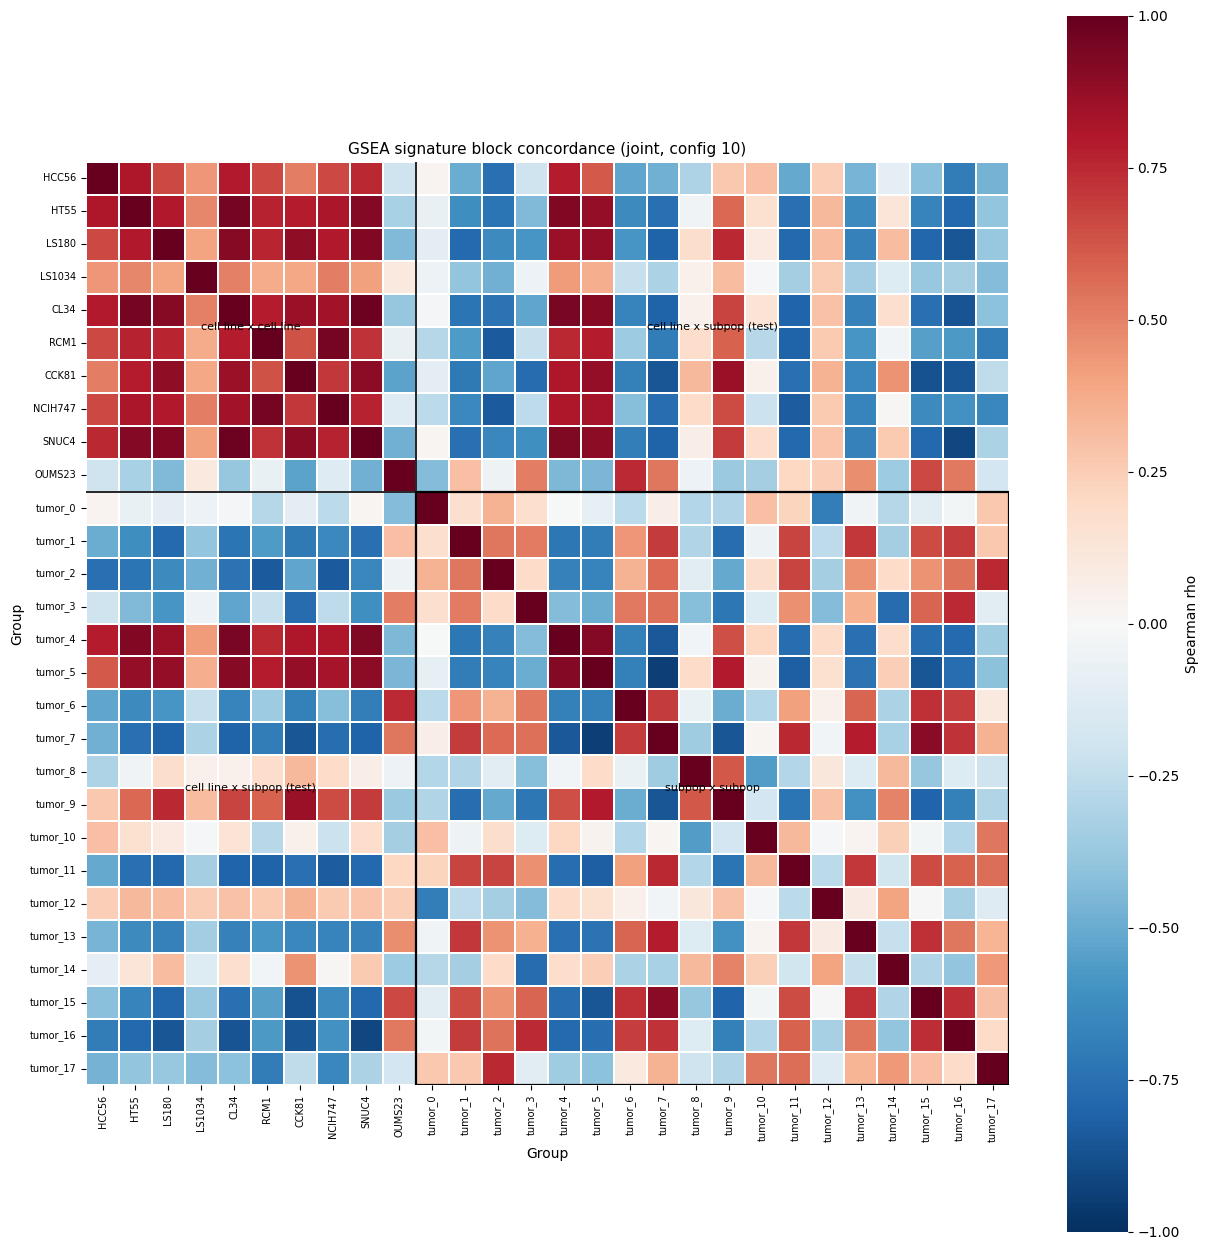

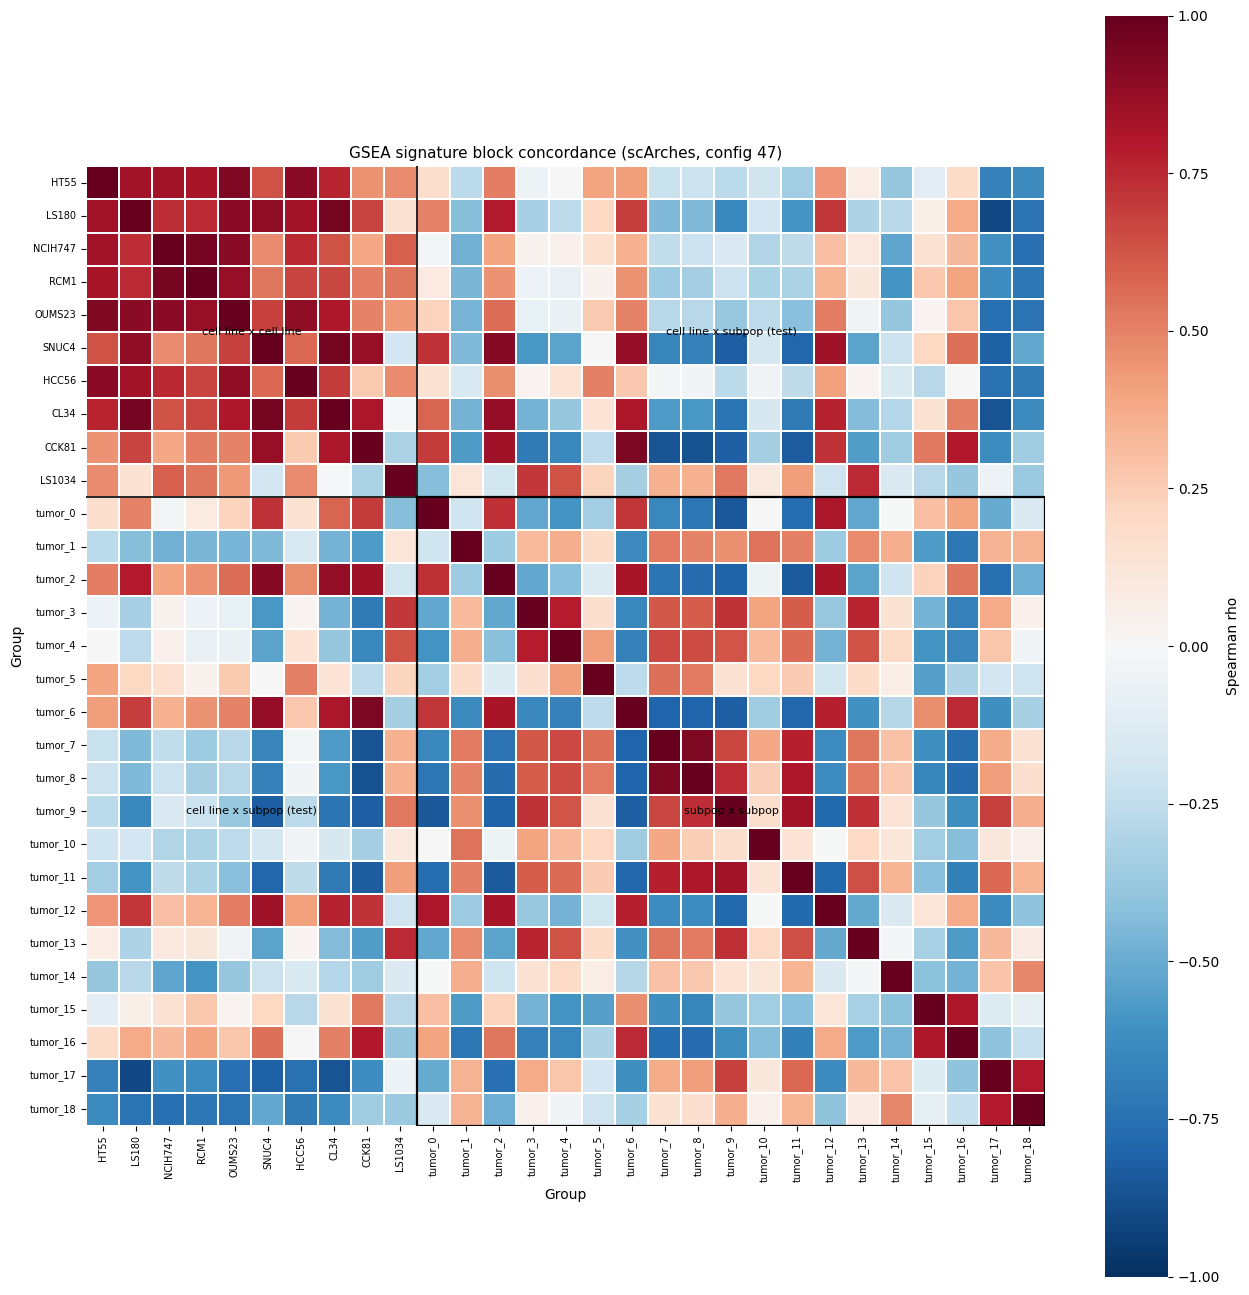

In [14]:
def signature_block_matrix(line_signature, tumor_signature, line_order, tumor_order):
    pathways = [p for p in line_signature.columns if p in set(tumor_signature.index)]
    line_profiles = line_signature.loc[line_order, pathways]
    subpop_profiles = tumor_signature.loc[pathways, tumor_order].T
    line_line = line_profiles.T.corr(method="spearman")
    subpop_subpop = subpop_profiles.T.corr(method="spearman")
    cross = pd.concat([line_profiles, subpop_profiles]).T.corr(method="spearman").loc[line_order, tumor_order]
    order = line_order + tumor_order
    block = pd.DataFrame(np.nan, index=order, columns=order)
    block.loc[line_order, line_order] = line_line
    block.loc[tumor_order, tumor_order] = subpop_subpop
    block.loc[line_order, tumor_order] = cross
    block.loc[tumor_order, line_order] = cross.T
    return block


def plot_signature_blocks(matrix, line_order, tumor_order, title, path):
    size = max(11, 0.45 * len(matrix))
    fig, ax = plt.subplots(figsize=(size, size))
    sns.heatmap(
        matrix, ax=ax, cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
        linewidths=0.15, cbar_kws={"label": "Spearman rho"},
    )
    n, m = len(line_order), len(tumor_order)
    ax.axhline(n, color="black", linewidth=1.2)
    ax.axvline(n, color="black", linewidth=1.2)
    ax.add_patch(Rectangle((n, n), m, m, fill=False, edgecolor="black", linewidth=1.6))
    ax.text(n / 2, n / 2, "cell line x cell line", ha="center", va="center", fontsize=8)
    ax.text(n + m / 2, n + m / 2, "subpop x subpop", ha="center", va="center", fontsize=8)
    ax.text(n + m / 2, n / 2, "cell line x subpop (test)", ha="center", va="center", fontsize=8)
    ax.text(n / 2, n + m / 2, "cell line x subpop (test)", ha="center", va="center", fontsize=8)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90, fontsize=7)
    ax.set_yticklabels(ax.get_yticklabels(), fontsize=7)
    ax.set_xlabel("Group")
    ax.set_ylabel("Group")
    ax.set_title(title, fontsize=11)
    plt.tight_layout()
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()


signature_blocks_joint = signature_block_matrix(line_signature_joint, tumor_signature_joint, line_order_joint, tumor_order_joint)
signature_blocks_arches = signature_block_matrix(line_signature_arches, tumor_signature_arches, line_order_arches, tumor_order_arches)
signature_blocks_joint.to_csv(OUT_DIR / "signature_blocks_joint.csv")
signature_blocks_arches.to_csv(OUT_DIR / "signature_blocks_arches.csv")

plot_signature_blocks(
    signature_blocks_joint, line_order_joint, tumor_order_joint,
    "GSEA signature block concordance (joint, config 10)", FIG_DIR / "full_signature_blocks_joint.png",
)
plot_signature_blocks(
    signature_blocks_arches, line_order_arches, tumor_order_arches,
    "GSEA signature block concordance (scArches, config 47)", FIG_DIR / "full_signature_blocks_arches.png",
)
